# MMIP Week 05 — Quiz 2：多模態深度學習分類

使用公開 **MM-IMDb**（電影海報＋劇情文字＋多個電影類型）完成 multi-label genre classification，比較兩種影像 backbone 組合：

1. ResNet-18 + DistilBERT
2. ViT-Base + DistilBERT

影像與文字各自萃取特徵，concatenate 後送入 fusion MLP。MM-IMDb 的劇情文字並非由標籤人工拼接，因此可用來觀察海報與文字資訊的互補效果。

| 配分要求 | 實作 |
|---|---|
| 多模態資料（5） | MM-IMDb image/text/labels |
| 雙 backbone＋融合分類（10） | image encoder + DistilBERT + fusion MLP |
| 訓練與推論（5） | BCE loss、多標籤預測範例 |
| 更換 backbone（10） | ResNet-18 → ViT-Base |
| 比較（5） | micro/macro F1、subset accuracy、Hamming loss |


In [1]:
%pip -q install -U "transformers>=4.45,<5" "datasets>=3,<5" "scikit-learn>=1.4,<2" pandas matplotlib tqdm


In [2]:
import json,random,time
from pathlib import Path
from collections import Counter
import numpy as np,pandas as pd,torch,torch.nn as nn,matplotlib.pyplot as plt
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import AutoImageProcessor,AutoModel,AutoTokenizer
from sklearn.metrics import f1_score,accuracy_score,hamming_loss,precision_score,recall_score
from tqdm.auto import tqdm

SEED=42
TRAIN_SIZE=4000; TEST_SIZE=1000
EPOCHS=3; BATCH_SIZE=8; LR=2e-4; TOP_GENRES=10
TEXT_MODEL="distilbert-base-uncased"; OUT=Path("quiz2_outputs"); OUT.mkdir(exist_ok=True)
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu");print(device)


cuda


## 1. 資料與標籤

MM-IMDb 每筆包含電影海報、plot 文字與 genre labels。為避免極少數類別造成不穩定，本實驗選訓練資料最常見的 10 個 genres；一部電影可同時屬於多類，故使用 multi-hot label 與 BCE loss。


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/405 [00:00<?, ?B/s]

data/train-00000-of-00004.parquet:   0%|          | 0.00/483M [00:00<?, ?B/s]

data/train-00001-of-00004.parquet:   0%|          | 0.00/482M [00:00<?, ?B/s]

data/train-00002-of-00004.parquet:   0%|          | 0.00/482M [00:00<?, ?B/s]

data/train-00003-of-00004.parquet:   0%|          | 0.00/479M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25959 [00:00<?, ? examples/s]

train=4000, test=1000
['Drama', 'Comedy', 'Thriller', 'Romance', 'Crime', 'Action', 'Horror', 'Adventure', 'Mystery', 'Fantasy']
[('Drama', 2126), ('Comedy', 1333), ('Thriller', 813), ('Romance', 797), ('Crime', 574), ('Action', 539), ('Horror', 458), ('Adventure', 406), ('Mystery', 343), ('Fantasy', 321)]


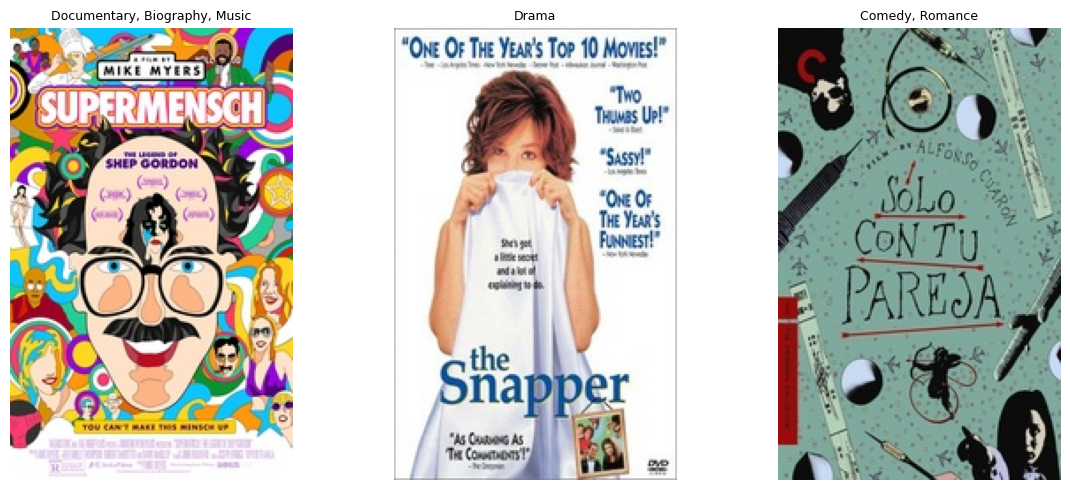

In [3]:
raw=load_dataset("pranavmr/MM-IMDb",split="train").shuffle(seed=SEED)
raw=raw.select(range(min(len(raw),TRAIN_SIZE+TEST_SIZE)))
train_ds=raw.select(range(TRAIN_SIZE));test_ds=raw.select(range(TRAIN_SIZE,TRAIN_SIZE+TEST_SIZE))
counts=Counter(g for row in train_ds for g in row["labels"])
genres=[g for g,_ in counts.most_common(TOP_GENRES)]; genre2id={g:i for i,g in enumerate(genres)}
print(f"train={len(train_ds)}, test={len(test_ds)}");print(genres);print(counts.most_common(TOP_GENRES))
fig,axes=plt.subplots(1,3,figsize=(12,5))
for ax,row in zip(axes,train_ds.select(range(3))):
 ax.imshow(row["image"]);ax.axis("off");ax.set_title(", ".join(row["labels"]),fontsize=9)
plt.tight_layout();plt.show()


## 2. 前處理與融合模型

預訓練 image/text encoders 保持凍結，訓練 projection layers 與 fusion classifier。此設定保留 backbone 的預訓練表徵，並讓兩種影像 backbone 在相同的文字模型與分類架構下進行公平比較。


In [4]:
tokenizer=AutoTokenizer.from_pretrained(TEXT_MODEL)

def multi_hot(labels):
 y=torch.zeros(TOP_GENRES)
 for g in labels:
  if g in genre2id:y[genre2id[g]]=1
 return y

def make_collate(processor):
 def collate(rows):
  pixels=processor(images=[r["image"].convert("RGB") for r in rows],return_tensors="pt")["pixel_values"]
  tok=tokenizer([r["text"] for r in rows],padding=True,truncation=True,max_length=192,return_tensors="pt")
  labels=torch.stack([multi_hot(r["labels"]) for r in rows])
  return pixels,tok,labels
 return collate

class FusionClassifier(nn.Module):
 def __init__(self,image_name):
  super().__init__();self.image=AutoModel.from_pretrained(image_name);self.text=AutoModel.from_pretrained(TEXT_MODEL)
  for p in self.image.parameters():p.requires_grad=False
  for p in self.text.parameters():p.requires_grad=False
  ih=getattr(self.image.config,"hidden_size",None) or self.image.config.hidden_sizes[-1]
  th=self.text.config.hidden_size
  self.image_proj=nn.Linear(ih,256);self.text_proj=nn.Linear(th,256)
  self.head=nn.Sequential(nn.ReLU(),nn.Dropout(.3),nn.Linear(512,256),nn.ReLU(),nn.Dropout(.2),nn.Linear(256,TOP_GENRES))
 def forward(self,pixels,tok):
  with torch.no_grad():
   io=self.image(pixel_values=pixels);to=self.text(**tok)
   if hasattr(io,"pooler_output") and io.pooler_output is not None:
    iv=io.pooler_output
    if iv.ndim>2:iv=iv.flatten(1)
   elif hasattr(io,"last_hidden_state") and io.last_hidden_state.ndim==4:iv=io.last_hidden_state.mean((-1,-2))
   else:iv=io.last_hidden_state[:,0]
   tv=to.last_hidden_state[:,0]
  z=torch.cat([self.image_proj(iv),self.text_proj(tv)],1);return self.head(z)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

## 3. 訓練兩種 backbone 組合

`pos_weight` 補償各 genre 的正負樣本不平衡。threshold 預設 0.5，並以相同資料、epoch、seed 比較。


In [5]:
positive=torch.zeros(TOP_GENRES)
for r in train_ds:positive+=multi_hot(r["labels"])
pos_weight=((len(train_ds)-positive)/positive.clamp_min(1)).to(device)

configs={"ResNet18+DistilBERT":"microsoft/resnet-18","ViT-Base+DistilBERT":"google/vit-base-patch16-224-in21k"}

def run_experiment(name,image_name):
 processor=AutoImageProcessor.from_pretrained(image_name);collate=make_collate(processor)
 tr=DataLoader(train_ds,BATCH_SIZE,shuffle=True,collate_fn=collate,num_workers=0)
 te=DataLoader(test_ds,BATCH_SIZE,shuffle=False,collate_fn=collate,num_workers=0)
 model=FusionClassifier(image_name).to(device);opt=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=LR)
 criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight);hist=[];start=time.perf_counter()
 for ep in range(1,EPOCHS+1):
  model.train();total=0
  for pixels,tok,y in tqdm(tr,desc=f"{name} epoch {ep}"):
   pixels=pixels.to(device);tok={k:v.to(device) for k,v in tok.items()};y=y.to(device)
   opt.zero_grad();loss=criterion(model(pixels,tok),y);loss.backward();opt.step();total+=loss.item()*len(y)
  hist.append({"epoch":ep,"loss":total/len(train_ds)});print(hist[-1])
 seconds=time.perf_counter()-start;model.eval();probs=[];truth=[]
 with torch.inference_mode():
  for pixels,tok,y in tqdm(te,desc="test"):
   tok={k:v.to(device) for k,v in tok.items()};probs.append(torch.sigmoid(model(pixels.to(device),tok)).cpu());truth.append(y)
 probs=torch.cat(probs).numpy();truth=torch.cat(truth).numpy().astype(int);pred=(probs>=.5).astype(int)
 metrics={"micro_f1":f1_score(truth,pred,average="micro",zero_division=0),
  "macro_f1":f1_score(truth,pred,average="macro",zero_division=0),
  "micro_precision":precision_score(truth,pred,average="micro",zero_division=0),
  "micro_recall":recall_score(truth,pred,average="micro",zero_division=0),
  "subset_accuracy":accuracy_score(truth,pred),"hamming_loss":hamming_loss(truth,pred),"training_seconds":seconds}
 return model,processor,hist,metrics,probs,truth

experiments={}
for name,image_name in configs.items():
 model,processor,hist,metrics,probs,truth=run_experiment(name,image_name)
 safe=name.replace("+","_")
 torch.save(model.state_dict(),OUT/f"{safe}.pt")
 pd.DataFrame(hist).to_csv(OUT/f"{safe}_history.csv",index=False)
 experiments[name]={"history":hist,"metrics":metrics,"probs":probs,"truth":truth}
 model.cpu();del model
 if torch.cuda.is_available():torch.cuda.empty_cache()


preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/46.8M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

...

ViT-Base+DistilBERT epoch 2:   0%|          | 0/500 [00:00<?, ?it/s]

{'epoch': 2, 'loss': 0.7919068264961243}


ViT-Base+DistilBERT epoch 3:   0%|          | 0/500 [00:00<?, ?it/s]

{'epoch': 3, 'loss': 0.7311484850049019}


test:   0%|          | 0/125 [00:00<?, ?it/s]

## 4. 比較與多模態推論結果

multi-label 任務的完全匹配 subset accuracy 很嚴格，因此主指標採 micro-F1 與 macro-F1；Hamming loss 越低越好。


,model,micro_f1,macro_f1,micro_precision,micro_recall,subset_accuracy,hamming_loss,training_seconds
0,ResNet18+DistilBERT,0.5421,0.5075,0.4155,0.7799,0.098,0.2532,148.6061
1,ViT-Base+DistilBERT,0.5857,0.5480,0.4705,0.7758,0.138,0.2109,249.5398


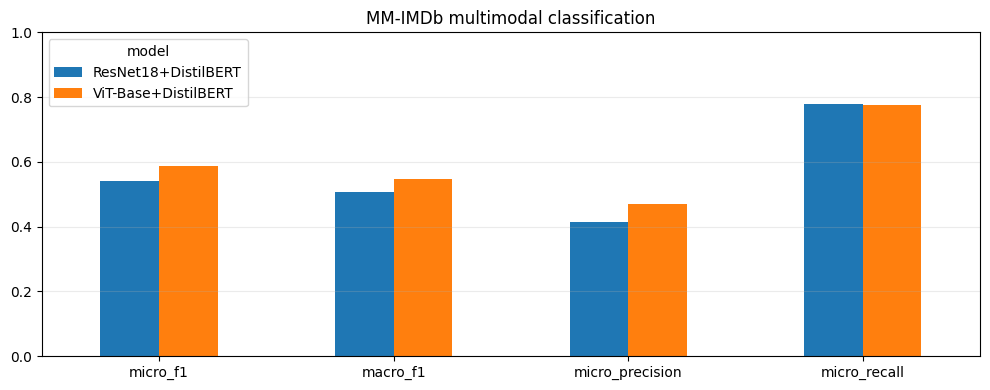

In [6]:
comparison=pd.DataFrame([{"model":k,**v["metrics"]} for k,v in experiments.items()])
comparison.to_csv(OUT/"backbone_comparison.csv",index=False);display(comparison.round(4))
ax=comparison.set_index("model")[["micro_f1","macro_f1","micro_precision","micro_recall"]].T.plot.bar(figsize=(10,4),rot=0)
ax.set_ylim(0,1);ax.grid(axis="y",alpha=.25);ax.set_title("MM-IMDb multimodal classification")
plt.tight_layout();plt.savefig(OUT/"backbone_comparison.png",dpi=160);plt.show()


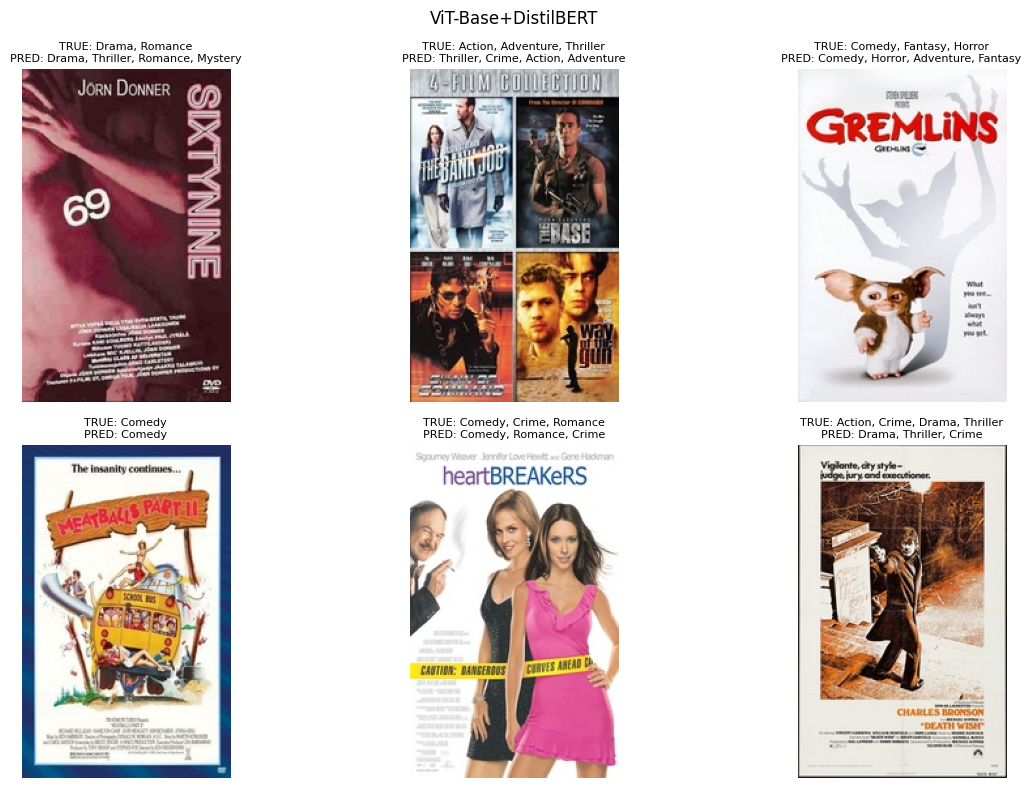

In [7]:
best_name=comparison.sort_values("micro_f1",ascending=False).iloc[0]["model"]
probs=experiments[best_name]["probs"]
fig,axes=plt.subplots(2,3,figsize=(13,8))
for i,ax in enumerate(axes.flat):
 row=test_ds[i];predicted=[genres[j] for j,p in enumerate(probs[i]) if p>=.5]
 ax.imshow(row["image"]);ax.axis("off");ax.set_title(f"TRUE: {', '.join([g for g in row['labels'] if g in genre2id])}\nPRED: {', '.join(predicted)}",fontsize=8)
plt.suptitle(best_name);plt.tight_layout();plt.savefig(OUT/"inference_examples.png",dpi=160);plt.show()


## 5. 實驗結論

本實驗使用 MM-IMDb 的 **4,000 筆訓練資料與 1,000 筆測試資料**，融合電影海報與劇情文字，預測最常見的 10 個電影類型。兩組模型共用 DistilBERT 文字 backbone 與相同 fusion classifier，僅將影像 backbone 由 ResNet-18 更換為 ViT-Base，因此可直接比較影像特徵對分類結果的影響。

ViT-Base + DistilBERT 的 micro-F1、macro-F1 與 subset accuracy 分別為 **0.5857、0.5480、0.1380**，均高於 ResNet-18 + DistilBERT 的 **0.5421、0.5075、0.0980**；Hamming loss 也由 **0.2532 降至 0.2109**。ViT 組合的 micro-precision 從 **0.4155 提升至 0.4705**，而 micro-recall 僅由 **0.7799 略降至 0.7758**，顯示主要改善來自減少誤判，而非犧牲大量召回率。

效能提升伴隨較高成本：ViT 組合訓練約 **249.54 秒**，ResNet 組合約 **148.61 秒**。因此，本次資料與設定下，ViT-Base + DistilBERT 提供較佳的整體多標籤分類品質，ResNet-18 + DistilBERT 則具有較低訓練成本。實驗限制包括只選用前 10 個 genres、凍結預訓練 backbone，以及使用 0.5 固定閾值；後續可解凍最後數層、為各類別調整 threshold，並加入 image-only／text-only ablation，以進一步量化每個模態的貢獻。


In [8]:
for name,exp in experiments.items():
 safe=name.replace("+","_");probs=exp["probs"];truth=exp["truth"]
 pred=(probs>=.5).astype(int);pd.DataFrame({"true":["|".join(genres[j] for j,x in enumerate(r) if x) for r in truth],"pred":["|".join(genres[j] for j,x in enumerate(r) if x) for r in pred]}).to_csv(OUT/f"{safe}_predictions.csv",index=False)
with open(OUT/"summary.json","w") as f:json.dump({r["model"]:{k:float(v) for k,v in r.items() if k!="model"} for r in comparison.to_dict("records")},f,indent=2)
print(OUT.resolve())


/content/quiz2_outputs
